<a href="https://colab.research.google.com/github/Andrew-Lever/Programming-BigDataAnalytics/blob/main/Loan_Applications_Random_Forest_and_GBDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1vv_PsWBnUJwSCkwKDoJAC-vXjtaEA4Ts)

# 5.02 Random Forest and Gradient Boosting Decision Trees
In this notebook we will extend the previous notebook by also looking at Random Forest and two GBDT implementations (the native scikit-learn implementation and also _eXtreme Gradient Boosting Decision Trees_ - _XGBDT_). The latter is basically a slighly more sophisticated implementation.

We start with a prepared dataset available on my.wbs:




In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('Final_Clean_Loan_Data.csv')

y_value = df['TARGET'] # set the y
y_values = np.ravel(y_value) # change to an array (list)

x_values = df.drop('TARGET', axis=1)
print(f'X values: \n {x_values.head()}\n')
print('\n')

# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.2, random_state=4567, stratify=y_value)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

X values: 
    Unnamed: 0  SK_ID_CURR  AMT_INCOME_TOTAL  AMT_CREDIT_x  AMT_ANNUITY_x  \
0           0      100008           99000.0      490495.5        27517.5   
1           1      100048          202500.0      604152.0        29196.0   
2           2      100054           99000.0      260640.0        26838.0   
3           3      100080          157500.0      450000.0        22500.0   
4           4      100100          202500.0      796396.5        38443.5   

   AMT_GOODS_PRICE  DAYS_EMPLOYED  DAYS_REGISTRATION  DAYS_ID_PUBLISH  \
0         454500.0          -1588              -4970             -477   
1         540000.0           -475              -3148             -513   
2         225000.0          -5332              -9197            -3283   
3         450000.0          -3154              -8118            -4143   
4         643500.0          -1094              -3134            -4180   

   OWN_CAR  OWN_HOME  PREV_APP_COUNT  PREV_AVG_APP_AMT  PREV_AVG_CREDIT_AMT  \
0        1   

## Modeling and Evaluation
We will set up algorithms for logistic regression (the previous winner) and then our new algorithms.

Just to look at the impact of hyperparameter optimisation, we will set them up initially with default hyperparameters and compare their performance (on the training data):

In [ ]:
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB
from sklearn.metrics import precision_recall_fscore_support

#LogR_algo = LogR()
#LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF()
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT()
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB()
XGB_model = XGB_algo.fit(X_train, Y_train)

models = [RF_model, GBDT_model, XGB_model]
names = ['Random Forest', 'GBDT', 'XGBDT']

for i in range(3):
  print(f"Model: {names[i]}")

  # predict based on training data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")


Model: Random Forest
Macro Precision: 0.9999733290659839
Macro Recall: 0.9997013142174432
Macro F1-score: 0.999837276666109


Model: GBDT
Macro Precision: 0.9595959595959596
Macro Recall: 0.5077658303464755
Macro F1-score: 0.49424148606811147


Model: XGBDT
Macro Precision: 0.9785561115082202
Macro Recall: 0.7491039426523297
Macro F1-score: 0.8215789823186694




Random Forest and XGBDT score perfectly - but is it overfitting? Let's hyperparameter tune them and see the scores again (on training data):

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
import warnings
warnings.filterwarnings("ignore")

# Create a hyperparameter search function optimizing for ROC-AUC to handle imbalance
def random_search(algo, hyperparameters, X_train, Y_train):
  # Changed scoring to 'roc_auc' which is much better for binary imbalanced targets
  clf = RandomizedSearchCV(algo, hyperparameters, cv=5, random_state=2015,
                          scoring='roc_auc', n_iter=20, refit=True, n_jobs=-1)

  # pass the data to fit/train
  clf.fit(X_train, Y_train)

  return clf.best_params_

# Calculate positive class scaling weight for XGBoost (Ratio of negative to positive samples)
scale_weight = (Y_train == 0).sum() / (Y_train == 1).sum()

# Re-initialize algorithms with class-balancing settings enabled
RF_algo = RF(class_weight='balanced', random_state=2015)
GBDT_algo = GBDT(random_state=2015) # GBDT does not have class_weight, but we will tune it for ROC-AUC
XGB_algo = XGB(scale_pos_weight=scale_weight, random_state=2015)

# Random Forest Parameters
RF_tuned_parameters = {
    'criterion': ['gini', 'entropy'],
    'n_estimators': randint(50, 500),
    'max_depth': randint(2, 7),
    'min_samples_split': randint(2, 7),
    'max_features': ['sqrt', 'log2', None]
}

print("Tuning Balanced Random Forest (ROC-AUC optimized)...")
RF_best_params = random_search(RF_algo, RF_tuned_parameters, X_train, Y_train)

# GBDT Parameters
GBDT_tuned_parameters = {
    'n_estimators': randint(25, 250),
    'learning_rate': uniform(loc=0.01, scale=0.5), # restricted learning rate scale for stability
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': randint(2, 7)
}

print("Tuning GBDT (ROC-AUC optimized)...")
GBDT_best_params = random_search(GBDT_algo, GBDT_tuned_parameters, X_train, Y_train)

# XGBDT Parameters
XGB_tuned_parameters = {
    'n_estimators': randint(25, 250),
    'eta': uniform(loc=0.01, scale=0.5),
    'objective': ['binary:logistic'],
    'max_depth': randint(2, 7)
}

print("Tuning Balanced XGBDT (ROC-AUC optimized)...")
XGB_best_params = random_search(XGB_algo, XGB_tuned_parameters, X_train, Y_train)

# Re-train the models with the optimized best parameters
RF_model = RF(class_weight='balanced', **RF_best_params, random_state=2015).fit(X_train, Y_train)
GBDT_model = GBDT(**GBDT_best_params, random_state=2015).fit(X_train, Y_train)
XGB_model = XGB(scale_pos_weight=scale_weight, **XGB_best_params, random_state=2015).fit(X_train, Y_train)

# Update models list
models = [RF_model, GBDT_model, XGB_model]
print("Tuning and Training Complete! Please run the evaluation cells to see the improved metrics.")

Tuning Balanced Random Forest (ROC-AUC optimized)...
Tuning GBDT (ROC-AUC optimized)...
Tuning Balanced XGBDT (ROC-AUC optimized)...
Tuning and Training Complete! Please run the evaluation cells to see the improved metrics.


In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc, confusion_matrix

for i, model in enumerate(models):
    print(f"==================== {names[i]} Evaluation (Balanced & ROC-AUC Optimized) ====================")
    predict = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(Y_test, probs)
    else:
        roc_auc = "N/A"

    print(classification_report(Y_test, predict, target_names=['Approved (0)', 'Default (1)']))
    print(f"ROC-AUC Score: {roc_auc if isinstance(roc_auc, str) else f'{roc_auc:.4f}'}")
    print("Confusion Matrix:")
    print(confusion_matrix(Y_test, predict))
    print("\n")

==================== Random Forest Evaluation (Balanced & ROC-AUC Optimized) ====================
              precision    recall  f1-score   support

Approved (0)       0.95      0.69      0.80      4688
 Default (1)       0.14      0.56      0.22       418

    accuracy                           0.68      5106
   macro avg       0.54      0.63      0.51      5106
weighted avg       0.88      0.68      0.75      5106

ROC-AUC Score: 0.6794
Confusion Matrix:
[[3234 1454]
 [ 183  235]]


==================== GBDT Evaluation (Balanced & ROC-AUC Optimized) ====================
              precision    recall  f1-score   support

Approved (0)       0.92      1.00      0.96      4688
 Default (1)       0.00      0.00      0.00       418

    accuracy                           0.92      5106
   macro avg       0.46      0.50      0.48      5106
weighted avg       0.84      0.92      0.88      5106

ROC-AUC Score: 0.6749
Confusion Matrix:
[[4688    0]
 [ 418    0]]


==================== 

In [ ]:
print("Best parameters set found on the training set:")
print('\nRandom Forest Best Parameters')
print(RF_best_params)

Best parameters set found on the training set:

Random Forest Best Parameters
{'criterion': 'gini', 'max_depth': 5, 'max_features': 'log2', 'min_samples_split': 4, 'n_estimators': 416}


In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# 1. Let's inspect the target class distribution
class_counts = Y_train.value_counts()
class_pcts = Y_train.value_counts(normalize=True) * 100
print("=== Class Distribution in Training Set ===")
for cls, count in class_counts.items():
    print(f"Class {cls}: {count} samples ({class_pcts[cls]:.2f}%)")
print("\n")

# 2. Detailed Evaluation with Class-Specific Reports and ROC-AUC for Test Data
for i, model in enumerate(models):
    print(f"==================== {names[i]} Detailed Evaluation ====================")
    predict = model.predict(X_test)

    # Get probability estimates for the positive class (class 1)
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(Y_test, probs)

        # Compute Precision-Recall AUC
        precision_curve, recall_curve, _ = precision_recall_curve(Y_test, probs)
        pr_auc = auc(recall_curve, precision_curve)
    else:
        roc_auc = "N/A"
        pr_auc = "N/A"

    # Display detailed class precision, recall, and f1-score
    print(classification_report(Y_test, predict, target_names=['Approved (0)', 'Default (1)']))
    print(f"ROC-AUC Score: {roc_auc if isinstance(roc_auc, str) else f'{roc_auc:.4f}'}")
    print(f"PR-AUC Score (Area Under Precision-Recall): {pr_auc if isinstance(pr_auc, str) else f'{pr_auc:.4f}'}")
    print("\n")

=== Class Distribution in Training Set ===
Class 0: 18746 samples (91.80%)
Class 1: 1674 samples (8.20%)


==================== Random Forest Detailed Evaluation ====================
              precision    recall  f1-score   support

Approved (0)       0.95      0.69      0.80      4688
 Default (1)       0.14      0.56      0.22       418

    accuracy                           0.68      5106
   macro avg       0.54      0.63      0.51      5106
weighted avg       0.88      0.68      0.75      5106

ROC-AUC Score: 0.6794
PR-AUC Score (Area Under Precision-Recall): 0.1615


==================== GBDT Detailed Evaluation ====================
              precision    recall  f1-score   support

Approved (0)       0.92      1.00      0.96      4688
 Default (1)       0.00      0.00      0.00       418

    accuracy                           0.92      5106
   macro avg       0.46      0.50      0.48      5106
weighted avg       0.84      0.92      0.88      5106

ROC-AUC Score: 0.6749

In [ ]:
# Extracting node purity statistics from the trained Random Forest model
leaf_impurities = []

for estimator in RF_model.estimators_:
    tree = estimator.tree_
    # Find nodes that are leaves (children left and right are both -1)
    for node_idx in range(tree.node_count):
        if tree.children_left[node_idx] == -1 and tree.children_right[node_idx] == -1:
            leaf_impurities.append(tree.impurity[node_idx])

# Convert to a numpy array for statistics
leaf_impurities = np.array(leaf_impurities)

print("=== Random Forest Node Purity Assessment ===")
print(f"Total Leaf Nodes evaluated: {len(leaf_impurities)}")
print(f"Average Gini Impurity at leaves: {leaf_impurities.mean():.4f}  (closer to 0.0 means higher purity)")
print(f"Minimum Gini Impurity at leaves: {leaf_impurities.min():.4f}")
print(f"Maximum Gini Impurity at leaves: {leaf_impurities.max():.4f}")

=== Random Forest Node Purity Assessment ===
Total Leaf Nodes evaluated: 12156
Average Gini Impurity at leaves: 0.3104  (closer to 0.0 means higher purity)
Minimum Gini Impurity at leaves: -0.0000
Maximum Gini Impurity at leaves: 0.5000


Our scores are ... a bit different from last time. In fact GBDT went up to perfect. However, the real test is the score on our test data:

In [ ]:
for i in range(3):
  print(f"Model: {names[i]}")

  # predict based on TEST data
  predict = models[i].predict(X_test)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_test, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Random Forest
Macro Precision: 0.5427899162634222
Macro Recall: 0.6260236866600257
Macro F1-score: 0.5105459402532084


Model: GBDT
Macro Precision: 0.4590677634155895
Macro Recall: 0.5
Macro F1-score: 0.4786604043291811


Model: XGBDT
Macro Precision: 0.544948111761109
Macro Recall: 0.639206076391724
Macro F1-score: 0.5009905669939221




Similar to last time, our best scorer for our prefered metric (_macro precision_) scores worse for everything else. We can make a good case to look further at both Random Forest and GBDT. So let's do that:

Random Forest Confusion Matrix


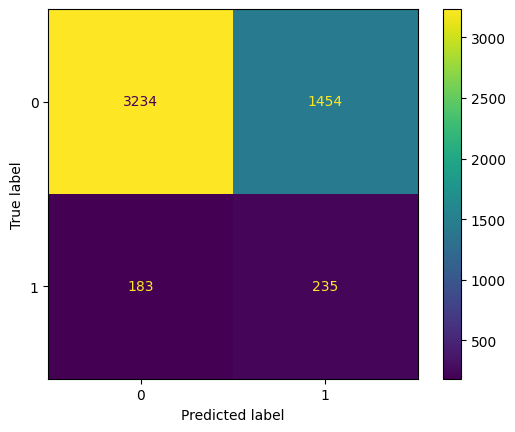

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# Random Forest
print("Random Forest Confusion Matrix")
predict = RF_model.predict(X_test)
CM.from_predictions(Y_test, predict)

GBDT Confusion Matrix


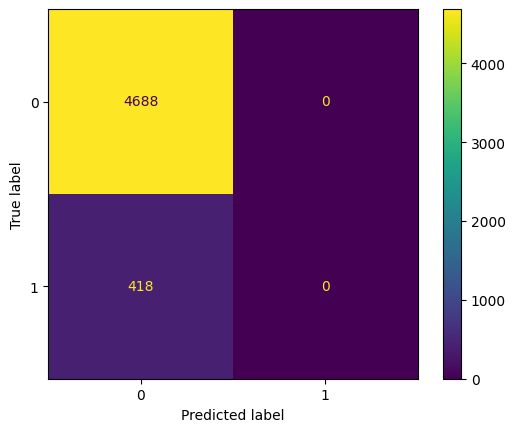

In [ ]:
# GBDT
print("GBDT Confusion Matrix")
predict = GBDT_model.predict(X_test)
print(CM.from_predictions(Y_test, predict))

We can see they are wrong in different ways. Because we care most about minimising cases we predict "0" (good to loan to) and in fact they are a "1" (bad to loan to), GBDT should be best. Random Forest misclassifies 56 cases in this way, while GBDT only 31. Also, random forest only predicts "1" a total of 4 times. GBDT is much more balanced in the predictions it makes for each class.

So GBDT is the winner.


XGB Confusion Matrix


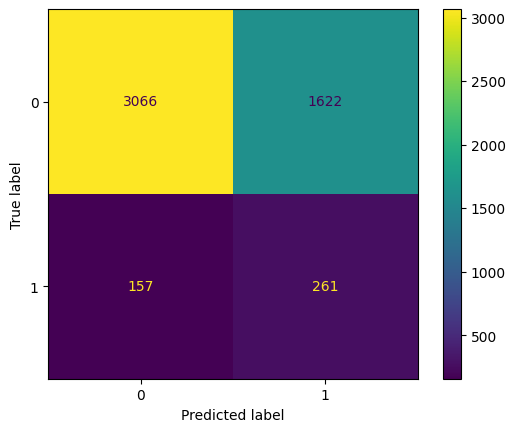

In [ ]:
# XGB
print("XGB Confusion Matrix")
predict = XGB_model.predict(X_test)
print(CM.from_predictions(Y_test, predict))

##We clearly see a trade-off between Random Forest and XGBoost model, as the former correctly predicts 3234 'good' applicants and 235 'bad' applicants, but also allows 183 'bad' applicants and disallows 1454 'good' applicants. For the latter, we see it correctly predicts 3066 'good' applicants (-168 'good' applicants allowed), as well as 261 'bad' applicants (+78 'bad' applicants caught) and 157 'bad' applicants allowed. However, it disallowed 1622 'good' applicants (+168 'good' applicants rejected).

##Therefore, this trade-off depends on the average cost of defaulting client vs the average cost of turning away a good client.